In [1]:
# SETUP — Jesse Leyva, Assignment 3: Agentic Genetic Algorithms
import random, json, copy, inspect, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from agents import *
from game_engine import Game, Tournament
random.seed(2122)
np.random.seed(2122)
# Recover the actual Unit 4 strategy from the completed previous notebook.
unit4 = json.loads(Path('unit_4_student_notebook.ipynb').read_text())
custom_source = next(''.join(c['source']) for c in unit4['cells']
                     if c['cell_type']=='code' and 'class MyCustomAgent' in ''.join(c['source']))
exec(custom_source)
print('Setup complete. Previous Unit 4 strategy preserved for comparison.')


Adaptive Forgiving
Setup complete. Previous Unit 4 strategy preserved for comparison.


In [2]:

# ============================================================================
# PART 1: THE EVOLVABLE AGENT (PROVIDED - Read but don't modify)
# ============================================================================

class EvolvableAgent(Agent):
    """
    An agent whose strategy is controlled by 6 genes (numbers from 0 to 1).
    
    Think of genes as "strategy dials" you can tune:
    
    Gene[0] - Initial Cooperation (0=hostile start, 1=friendly start)
    Gene[1] - Cooperation Response (if opponent cooperates, how likely to cooperate back?)
    Gene[2] - Defection Response (if opponent defects, how likely to defect back?)
    Gene[3] - Forgiveness (after retaliation, chance to forgive)
    Gene[4] - Memory Length (0=last 1 round, 1=last 10 rounds)
    Gene[5] - Retaliation Threshold (what % of defections triggers retaliation)
    """
    
    def __init__(self, genes=None, name="Evolved Agent"):
        if genes is None:
            # Create random genes if none provided
            genes = [random.random() for _ in range(6)]
        
        self.genes = genes
        super().__init__(name, f"Genes: [{', '.join([f'{g:.2f}' for g in genes])}]")
    
    def choose_action(self) -> bool:
        """Decision logic based on genes - SIMPLIFIED FOR LEARNING"""
        
        # First 3 rounds: use initial cooperation gene
        if self.round_num < 3:
            return random.random() < self.genes[0]
        
        # Calculate memory window (gene[4])
        memory_length = max(1, int(self.genes[4] * 10) + 1)
        recent_history = self.history[-memory_length:]
        
        # Calculate opponent's recent COOPERATION rate (not defection!)
        cooperation_rate = sum(recent_history) / len(recent_history)
        
        # If opponent is mostly cooperating, reciprocate
        if cooperation_rate >= 0.5:
            return random.random() < self.genes[1]  # gene[1] = cooperate response
        
        # If opponent is mostly defecting, retaliate or forgive
        else:
            # Retaliate with probability gene[2]
            if random.random() < self.genes[2]:
                return UNDERCUT
            # Or forgive with probability gene[3]
            elif random.random() < self.genes[3]:
                return INVEST
            else:
                return UNDERCUT


In [3]:
# PART 2: OPPONENT ECOSYSTEM — reproducible, disjoint train/validation/test split
full_opponent_pool = [AlwaysInvestAgent(), AlwaysUndercutAgent(), TitForTatAgent(),
    GrimTriggerAgent(), PavlovAgent(), TitForTwoTatsAgent(), GenerousTitForTatAgent(),
    AdaptiveAgent(), SuspiciousTitForTatAgent(), GradualAgent(), ProberAgent(),
    HardMajorityAgent(), SoftMajorityAgent(), RandomAgent(.9), RandomAgent(.7),
    RandomAgent(.5), RandomAgent(.3), RandomAgent(.1)]
# Stratified random sampling prevents accidentally omitting entire opponent types.
split_rng = random.Random(2122)
groups = [full_opponent_pool[:2], full_opponent_pool[2:8],
          full_opponent_pool[8:13], full_opponent_pool[13:]]
counts = [2, 3, 3, 2]
opponent_pool = [o for group,k in zip(groups,counts) for o in split_rng.sample(group,k)]
remaining = [o for o in full_opponent_pool if o not in opponent_pool]
validation_pool = split_rng.sample(remaining,3)
test_pool = [o for o in remaining if o not in validation_pool]
for label,pool in [('Training',opponent_pool),('Validation (tuning only)',validation_pool),
                   ('Unseen test (never used for selection)',test_pool)]:
    print(label, ':', ', '.join(o.name for o in pool))
print('Library size:',len(full_opponent_pool),'— the starter has 18, not 19, opponents.')


Training : Always Undercut, Always Invest, Grim Trigger, Tit-for-Tat, Pavlov, Soft Majority, Hard Majority, Prober, Random (0.1), Random (0.9)
Validation (tuning only) : Gradual, Adaptive, Generous Tit-for-Tat
Unseen test (never used for selection) : Tit-for-Two-Tats, Suspicious Tit-for-Tat, Random (0.7), Random (0.5), Random (0.3)
Library size: 18 — the starter has 18, not 19, opponents.


In [4]:
# PART 3: GENETIC ALGORITHM FUNCTIONS

def clone_agent(agent):
    cloned = copy.deepcopy(agent)
    cloned.genes = list(agent.genes)
    cloned.reset()
    return cloned


def initialize_population(pop_size, agent_class=EvolvableAgent):
    if pop_size < 2:
        raise ValueError('Population must contain at least two agents')
    population = []
    for i in range(pop_size):
        agent = agent_class(name=f'Candidate {i}')
        # Mix continuous genes and random boundary genes for broader coverage.
        if i % 3 == 0:
            agent.genes = [float(random.choice([0,1])) for _ in agent.genes]
        population.append(agent)
    return population


def fitness_details(agent, opponents, num_rounds=60, seeds=(101,202)):
    """Repeated games; maximize own payoff, with a small lower-tail safety term.

    Fixed common seeds make candidate comparisons reproducible. Saving RNG state
    prevents evaluation from changing selection/crossover randomness. Fresh agent
    copies plus Game.reset prevent history leakage between candidates or games.
    """
    if not opponents or num_rounds < 1 or not seeds:
        raise ValueError('Need opponents, positive rounds, and evaluation seeds')
    state = random.getstate()
    scores = []
    try:
        for j, opponent in enumerate(opponents):
            for seed in seeds:
                random.seed(seed + 997*j)
                score, _ = Game(clone_agent(agent), copy.deepcopy(opponent),num_rounds).play()
                scores.append(score / num_rounds)
    finally:
        random.setstate(state)
    mean = float(np.mean(scores))
    lower = float(np.quantile(scores,.2))
    return {'fitness': num_rounds*(.9*mean + .1*lower),
            'mean_per_round': mean, 'lower_tail_per_round': lower}


def evaluate_fitness(agent, opponents, num_rounds=60, seeds=(101,202)):
    return fitness_details(agent, opponents, num_rounds, seeds)['fitness']


def tournament_selection(population, fitnesses, tournament_size=3, exploration=.08):
    """Small tournaments favor good agents; random selection preserves diversity."""
    if not population or len(population)!=len(fitnesses):
        raise ValueError('Population and fitness lengths must match')
    if tournament_size < 1 or not 0 <= exploration <= 1:
        raise ValueError('Invalid selection parameters')
    selected=[]
    for _ in population:
        if random.random() < exploration:
            winner=random.randrange(len(population))
        else:
            indices=random.sample(range(len(population)),min(tournament_size,len(population)))
            winner=max(indices,key=lambda i:fitnesses[i])
        selected.append(clone_agent(population[winner]))
    return selected


def crossover_and_mutate(parent1,parent2,mutation_rate=.15,mutation_scale=.15):
    """Uniform inheritance, occasional blend crossover, bounded Gaussian mutation."""
    if type(parent1)!=type(parent2) or len(parent1.genes)!=len(parent2.genes):
        raise ValueError('Parents must have matching class and genome length')
    if not 0 <= mutation_rate <= 1 or mutation_scale < 0:
        raise ValueError('Invalid mutation parameters')
    genes=[]
    for a,b in zip(parent1.genes,parent2.genes):
        if random.random() < .2:
            alpha=random.random(); value=alpha*a+(1-alpha)*b
        else:
            value=random.choice([a,b])
        if random.random() < mutation_rate:
            # Rare reset escapes a local optimum; usually make a small change.
            value=random.random() if random.random()<.08 else value+random.gauss(0,mutation_scale)
        genes.append(max(0.,min(1.,value)))
    return type(parent1)(genes=genes)


def evolve(generations=30,pop_size=28,opponents=None,mutation_rate=.15,elitism=2,
           agent_class=EvolvableAgent,seed=21,plot=True):
    if opponents is None: opponents=opponent_pool
    if generations<1 or not 0<=elitism<pop_size or not 0<=mutation_rate<=1:
        raise ValueError('Invalid evolution settings')
    random.seed(seed)
    population=initialize_population(pop_size,agent_class)
    history=[]; best_agent=None; best_fitness=-float('inf'); stalled=0
    for generation in range(generations):
        # A consistent repeated-game objective allows meaningful elite comparison.
        fitnesses=[evaluate_fitness(a,opponents) for a in population]
        order=sorted(range(pop_size),key=lambda i:fitnesses[i],reverse=True)
        winner=order[0]
        if fitnesses[winner]>best_fitness+1e-9:
            best_fitness=fitnesses[winner]; best_agent=clone_agent(population[winner]); stalled=0
        else: stalled+=1
        diversity=float(np.mean(np.std([a.genes for a in population],axis=0)))
        rate=min(.5,mutation_rate*(1.6 if stalled>=5 or diversity<.08 else 1))
        scale=.20-(.12*generation/max(1,generations-1))
        history.append(dict(generation=generation+1,best=best_fitness,
                            average=float(np.mean(fitnesses)),diversity=diversity,mutation=rate))
        if generation==0 or (generation+1)%10==0 or generation==generations-1:
            print(f'Generation {generation+1}: best={best_fitness:.2f}, '
                  f'average={np.mean(fitnesses):.2f}, diversity={diversity:.3f}')
        if generation==generations-1: break
        next_population=[clone_agent(population[i]) for i in order[:elitism]]
        selected=tournament_selection(population,fitnesses)
        while len(next_population)<pop_size:
            a,b=random.sample(selected,2)
            next_population.append(crossover_and_mutate(a,b,rate,scale))
        population=next_population
    best_agent.evolution_history=history
    best_agent.final_fitness=best_fitness
    best_agent.training_config=dict(generations=generations,pop_size=pop_size,
                                    mutation_rate=mutation_rate,elitism=elitism,seed=seed)
    if plot:
        frame=pd.DataFrame(history)
        frame.plot(x='generation',y=['best','average'],title=agent_class.__name__+' evolution')
        plt.ylabel('Fitness: risk-adjusted score per 60-round game');plt.tight_layout();plt.show()
    return best_agent


def benchmark(agent, opponents, seeds=(301,302,303,304,305), rounds=100):
    rows=[]; state=random.getstate()
    try:
        for j,opponent in enumerate(opponents):
            scores=[]; opposing=[]; outcomes=[]
            for seed in seeds:
                random.seed(seed+997*j)
                mine,theirs=Game(copy.deepcopy(agent),copy.deepcopy(opponent),rounds).play()
                scores.append(mine);opposing.append(theirs)
                outcomes.append('W' if mine>theirs else 'L' if mine<theirs else 'T')
            rows.append({'Opponent':opponent.name,'Your Score':float(np.mean(scores)),
                         'Opp Score':float(np.mean(opposing)),
                         'Score SD':float(np.std(scores,ddof=1)) if len(scores)>1 else 0.,
                         'Wins':outcomes.count('W'),'Losses':outcomes.count('L'),
                         'Ties':outcomes.count('T'),
                         'Result':'W' if np.mean(scores)>np.mean(opposing) else
                                  'L' if np.mean(scores)<np.mean(opposing) else 'T'})
    finally: random.setstate(state)
    return pd.DataFrame(rows)


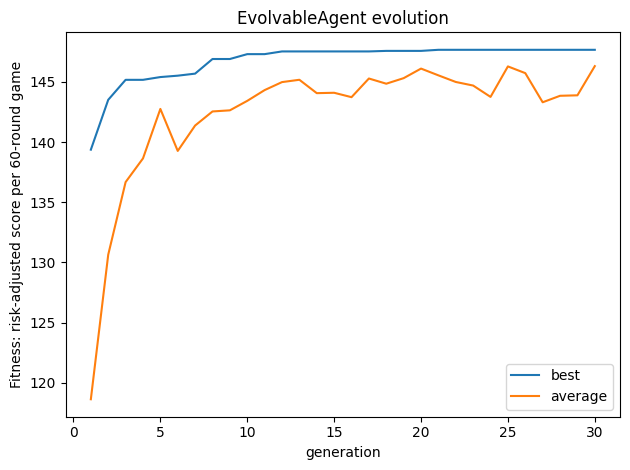

Generation 1: best=139.37, average=118.63, diversity=0.379
Generation 10: best=147.31, average=143.43, diversity=0.094
Generation 20: best=147.58, average=146.11, diversity=0.066
Generation 30: best=147.67, average=146.31, diversity=0.070
Original evolved genes: [0.6441403510190016, 0.9890810929895767, 0.7746154732811077, 0.0120912284638947, 0.8474059666882865, 0.062268616154764]


In [5]:
# PART 4: RUN EVOLUTION!
# Compare a random population (no inheritance) with the completed baseline GA.
random.seed(21)
untrained_candidates=initialize_population(28)
random_baseline=max(untrained_candidates,key=lambda a:evaluate_fitness(a,opponent_pool))
random_baseline.name='Random-search baseline'
my_evolved_agent=evolve(generations=30,pop_size=28,mutation_rate=.15,elitism=2,seed=21)
my_evolved_agent.name='Original evolved agent'
print('Original evolved genes:',my_evolved_agent.genes)


In [6]:
# PART 5: TEST YOUR AGENT — benchmark opponents from the required analysis table
analysis_names=['Always Invest','Always Undercut','Tit-for-Tat','Grim Trigger','Pavlov',
 'Tit-for-Two-Tats','Generous Tit-for-Tat','Adaptive','Random (0.7)','Random (0.3)']
analysis_pool=[next(o for o in full_opponent_pool if o.name==name) for name in analysis_names]
initial_benchmark=benchmark(my_evolved_agent,analysis_pool)
display(initial_benchmark.round(2))
print('Each row averages five independent 100-round games; W/L/T compares mean scores.')
print('Untrained random-search score:',benchmark(random_baseline,analysis_pool)['Your Score'].mean())
print('Evolved baseline score:',initial_benchmark['Your Score'].mean())


,Opponent,Your Score,Opp Score,Score SD,Wins,Losses,Ties,Result
0,Always Invest,304.0,294.0,3.46,5,0,0,W
1,Always Undercut,98.0,108.0,0.00,0,5,0,L
2,Tit-for-Tat,298.4,298.4,1.14,0,0,5,T
3,Grim Trigger,136.8,145.8,76.14,0,5,0,L
4,Pavlov,279.2,185.2,13.85,4,0,1,W
5,Tit-for-Two-Tats,302.8,293.8,2.28,4,0,1,W
6,Generous Tit-for-Tat,298.8,298.8,0.84,0,0,5,T
7,Adaptive,302.6,294.6,2.41,5,0,0,W
8,Random (0.7),233.2,324.2,10.71,0,5,0,L
9,Random (0.3),211.0,126.0,7.97,5,0,0,W


Each row averages five independent 100-round games; W/L/T compares mean scores.
Untrained random-search score: 264.02
Evolved baseline score: 246.48000000000002


# Unit 5 Part 2: Benchmark Analysis

Jesse Leyva

## Performance Summary

These are averages of five 100-round matches per opponent using seeds 301–305. W/L/T compares the average scores; SD measures variation in my agent's scores, not uncertainty across opponent types.

| Opponent | Result (W/L/T) | Your Score | Opp Score | Score SD |
|---|---|---:|---:|---:|
| Always Invest | W | 304.00 | 294.00 | 3.46 |
| Always Undercut | L | 98.00 | 108.00 | 0.00 |
| Tit-for-Tat | T | 298.40 | 298.40 | 1.14 |
| Grim Trigger | L | 136.80 | 145.80 | 76.14 |
| Pavlov | W | 279.20 | 185.20 | 13.85 |
| Tit-for-Two-Tats | W | 302.80 | 293.80 | 2.28 |
| Generous Tit-for-Tat | T | 298.80 | 298.80 | 0.84 |
| Adaptive | W | 302.60 | 294.60 | 2.41 |
| Random (0.7) | L | 233.20 | 324.20 | 10.71 |
| Random (0.3) | W | 211.00 | 126.00 | 7.97 |
| **Total** | **5 W / 3 L / 2 T** | **2464.80** | **2368.80** | — |

Across the 50 individual matches, the original agent had 23 wins, 15 losses, and 12 ties.

### 1. What was your agent's worst loss and why?

The original agent's worst average loss was against Random (0.7), with 233.20 points compared with 324.20, a 91-point difference. The agent usually interpreted that opponent's frequent cooperation as a reason to cooperate back. However, the opponent's random undercuts still earned five points while my agent earned zero on those rounds. This showed that cooperation rate alone does not tell the agent whether the opponent will actually respond to its behavior.

### 2. What pattern do you see in wins vs. losses?

The original agent beat forgiving or predictable opponents like Always Invest and Pavlov, but lost to Always Undercut, Grim Trigger, and Random (0.7). It tied Tit-for-Tat and Generous Tit-for-Tat, where matching cooperation produced good scores without a head-to-head win. Grim Trigger's score SD of 76.14 also showed how one early undercut could change the rest of a match.

### 3. What would make an agent more competitive?

I would separate responses to all four previous-action combinations instead of relying mainly on a recent cooperation rate. I would also add bounded repair after mutual undercutting and use observed responses to decide whether an opponent is unresponsive to punishment. Repeated evaluation and a separate validation group should make it harder to select a strategy that only looks good because of one lucky match.


In [7]:
# PART 6: IMPROVED AGENT'S ACTION TAKING
class ImprovedEvolvableAgent(Agent):
    """Memory-one responses plus bounded retaliation, recovery and probing.

    Genes 0..3: cooperation after (my,last opponent) = CC, CD, DC, DD.
    Gene 4: opening cooperation. Gene 5: recent memory window (2..12).
    Gene 6: sustained-defection threshold (.25..85).
    Gene 7: deadlock-repair interval (4..24).
    Gene 8: cautious probing interval (12..52); >=.8 disables probing.
    Gene 9: exploiting unresponsive cooperation (.5 threshold).
    Probability extremes are snapped to 0/1 to allow reliable reciprocal rules.
    """
    def __init__(self,genes=None,name='Improved Agent'):
        values=[random.random() for _ in range(10)] if genes is None else list(genes)
        if len(values)!=10 or any(not np.isfinite(g) or not 0<=g<=1 for g in values):
            raise ValueError('Expected ten finite genes in [0,1]')
        self.genes=values
        super().__init__(name,'Evolved reciprocity with bounded repair and cautious opponent testing')

    def choose_action(self) -> bool:
        # Keep the complete action logic self-contained for the tournament export.
        def probability(value):
            return 0. if value<.15 else 1. if value>.85 else value
        g=self.genes
        if not self.history:
            return self._apply_noise(random.random()<probability(g[4]))
        window=2+int(g[5]*10)
        recent=self.history[-window:]
        defections=1-sum(recent)/len(recent)
        # Four response genes distinguish retaliation from reconciliation.
        index=(0 if self.my_history[-1] else 2)+(0 if self.history[-1] else 1)
        cooperate=probability(g[index])
        if len(recent)>=window and defections>.25+.60*g[6]:
            cooperate=min(cooperate,probability(g[3]))
        # A scheduled olive branch can break a DD deadlock. Persistent hostile
        # opponents limit repair to one costly offer per interval.
        repair_interval=4+int(g[7]*20)
        if len(self.history)>=3 and not any(self.history[-3:]) and not any(self.my_history[-3:]):
            cooperate=1. if self.round_num%repair_interval==0 else cooperate
        # Probe only long cooperative streaks. The gene can disable probes when
        # irreversible punishers make exploration too expensive.
        probe_interval=12+int(g[8]*40)
        if g[8]<.8 and len(self.history)>=12 and all(self.history[-12:]):
            if self.round_num%probe_interval==0:
                cooperate=0.
        # Require multiple observed responses before treating cooperation as
        # unresponsive. No access to opponent identity, future moves or horizon.
        responses=[self.history[i] for i in range(1,len(self.history))
                   if not self.my_history[i-1]]
        if g[9]>.5 and len(responses)>=4 and sum(responses)/len(responses)>.85:
            cooperate=0.
        return self._apply_noise(random.random()<cooperate)

    def save_to_file(self,filename):
        Path(filename).write_text(json.dumps({'name':self.name,'genes':self.genes,
                                            'description':self.description},indent=2))


Experiment 1 {'generations': 25, 'pop_size': 28, 'mutation_rate': 0.1, 'elitism': 2, 'seed': 42}
Generation 1: best=151.79, average=118.43, diversity=0.369
Generation 10: best=162.44, average=156.07, diversity=0.100
Generation 20: best=162.86, average=156.68, diversity=0.072
Generation 25: best=162.86, average=159.59, diversity=0.080
Experiment 2 {'generations': 35, 'pop_size': 32, 'mutation_rate': 0.18, 'elitism': 3, 'seed': 42}
Generation 1: best=151.79, average=118.25, diversity=0.368
Generation 10: best=159.69, average=151.54, diversity=0.143
Generation 20: best=163.20, average=155.32, diversity=0.095
Generation 30: best=165.71, average=159.10, diversity=0.086
Generation 35: best=166.21, average=157.01, diversity=0.078
Experiment 3 {'generations': 35, 'pop_size': 32, 'mutation_rate': 0.28, 'elitism': 2, 'seed': 42}
Generation 1: best=151.79, average=118.25, diversity=0.368
Generation 10: best=159.89, average=152.49, diversity=0.149
Generation 20: best=162.33, average=157.55, divers

,trial,generations,pop_size,mutation_rate,elitism,seed,training_fitness,validation_score
0,1,25,28,0.10,2,42,162.860,282.533
1,2,35,32,0.18,3,42,166.205,242.067
2,3,35,32,0.28,2,42,162.680,290.267


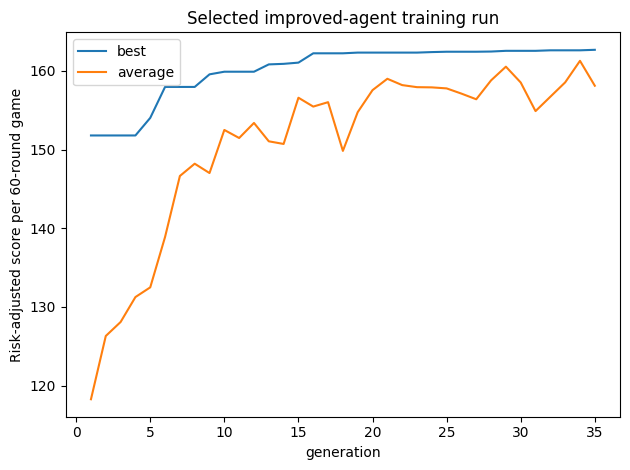

Selected using validation only: {'generations': 35, 'pop_size': 32, 'mutation_rate': 0.28, 'elitism': 2, 'seed': 42}
Final genes: [1.0, 0.10806718135960316, 0.9596804605582223, 0.028486584206704694, 0.8419352739009551, 0.41002771947750827, 0.0, 1.0, 0.9481837114046969, 0.7627127683594422]


In [8]:
# PART 7: EVOLVE YOUR IMPROVED AGENT — documented tuning experiments
# Validation opponents choose hyperparameters; unseen test opponents stay unused.
def evolve_improved(**kwargs):
    return evolve(agent_class=ImprovedEvolvableAgent,**kwargs)

experiments=[
    dict(generations=25,pop_size=28,mutation_rate=.10,elitism=2,seed=42),
    dict(generations=35,pop_size=32,mutation_rate=.18,elitism=3,seed=42),
    dict(generations=35,pop_size=32,mutation_rate=.28,elitism=2,seed=42)]
trial_agents=[]; trial_rows=[]
for i,config in enumerate(experiments,1):
    print('Experiment',i,config)
    candidate=evolve_improved(**config,plot=False)
    # Independent seeds and validation identities differ from fitness training.
    validation=benchmark(candidate,validation_pool,seeds=(401,402,403,404,405))
    validation_score=float(validation['Your Score'].mean())
    trial_agents.append(candidate)
    trial_rows.append(dict(trial=i,**config,training_fitness=candidate.final_fitness,
                           validation_score=validation_score))
experiment_results=pd.DataFrame(trial_rows)
display(experiment_results.round(3))
best_trial=int(experiment_results['validation_score'].idxmax())
my_improved_agent=trial_agents[best_trial]
my_improved_agent.name='Leyva Adaptive Guard'
selected_config=experiments[best_trial]
print('Selected using validation only:',selected_config)
print('Final genes:',my_improved_agent.genes)
history=pd.DataFrame(my_improved_agent.evolution_history)
history.plot(x='generation',y=['best','average'],title='Selected improved-agent training run')
plt.ylabel('Risk-adjusted score per 60-round game');plt.tight_layout();plt.show()


In [9]:
# PART 8.1: ORIGINAL VS IMPROVED AND GENERALIZATION
models={'Random search':random_baseline,'Original GA':my_evolved_agent,
        'Improved GA':my_improved_agent,'Unit 4 custom':MyCustomAgent(),
        'Tit-for-Tat':TitForTatAgent(),'Always Undercut':AlwaysUndercutAgent()}
comparison_rows=[]; evaluation_tables={}
for label,agent in models.items():
    table=benchmark(agent,full_opponent_pool,seeds=tuple(range(601,611)))
    table['Split']=table['Opponent'].map(lambda name: 'Training' if name in [o.name for o in opponent_pool]
        else 'Validation' if name in [o.name for o in validation_pool] else 'Unseen test')
    evaluation_tables[label]=table
    for split in ['Training','Validation','Unseen test','All']:
        part=table if split=='All' else table[table['Split']==split]
        comparison_rows.append({'Model':label,'Split':split,
            'Mean Score':float(part['Your Score'].mean()),
            'Match Win %':100*float(part['Wins'].sum())/(10*len(part)),
            'Match Tie %':100*float(part['Ties'].sum())/(10*len(part))})
comparison=pd.DataFrame(comparison_rows)
display(comparison.round(2))
display(evaluation_tables['Improved GA'].round(2))
# Stress tests use changed behavior and noise; these results do not tune the model.
stress_pool=[TitForTatAgent(noise=.1),GenerousTitForTatAgent(noise=.1),
             GrimTriggerAgent(noise=.1),RandomAgent(.6),RandomAgent(.2),MyCustomAgent(noise=.1)]
for i,o in enumerate(stress_pool):o.name='Stress '+str(i)+' '+o.name
stress_results=benchmark(my_improved_agent,stress_pool,seeds=tuple(range(701,711)))
display(stress_results.round(2))


,Model,Split,Mean Score,Match Win %,Match Tie %
0,Random search,Training,240.71,0.00,69.00
1,Random search,Validation,300.00,0.00,100.00
2,Random search,Unseen test,251.36,0.00,24.00
3,Random search,All,253.55,0.00,61.67
4,Original GA,Training,226.48,46.00,21.00
5,Original GA,Validation,290.07,46.67,40.00
6,Original GA,Unseen test,221.34,42.00,22.00
7,Original GA,All,235.65,45.00,24.44
8,Improved GA,Training,259.76,23.00,62.00
9,Improved GA,Validation,296.27,10.00,90.00


,Opponent,Your Score,Opp Score,Score SD,Wins,Losses,Ties,Result,Split
0,Always Invest,300.0,300.0,0.00,0,0,10,T,Training
1,Always Undercut,95.2,119.2,0.42,0,10,0,L,Training
2,Tit-for-Tat,265.0,264.0,73.79,2,0,8,W,Training
3,Grim Trigger,300.0,300.0,0.00,0,0,10,T,Training
4,Pavlov,298.8,251.8,2.53,2,0,8,W,Training
5,Tit-for-Two-Tats,300.4,299.4,0.84,2,0,8,W,Unseen test
6,Generous Tit-for-Tat,300.0,300.0,0.00,0,0,10,T,Validation
7,Adaptive,300.4,299.4,0.84,2,0,8,W,Validation
8,Suspicious Tit-for-Tat,118.3,118.3,4.35,0,0,10,T,Unseen test
9,Gradual,288.4,279.9,36.68,1,0,9,W,Validation


,Opponent,Your Score,Opp Score,Score SD,Wins,Losses,Ties,Result
0,Stress 0 Tit-for-Tat,167.9,128.9,13.71,10,0,0,W
1,Stress 1 Generous Tit-for-Tat,188.2,112.2,17.66,10,0,0,W
2,Stress 2 Grim Trigger,145.7,113.7,13.05,10,0,0,W
3,Stress 3 Random (0.6),303.9,114.4,19.43,10,0,0,W
4,Stress 4 Random (0.2),171.6,97.1,14.53,10,0,0,W
5,Stress 5 Adaptive Forgiving,179.7,149.2,28.50,10,0,0,W


In [10]:
# PART 8.2: FULL TOURNAMENT — use the provided engine, same seeds, 5 repeats
import contextlib,io
rank_rows=[]; tournament_details={}
for label,agent in [('Original GA',my_evolved_agent),('Improved GA',my_improved_agent)]:
    run_rows=[]; leaderboards=[]
    for seed in range(801,806):
        random.seed(seed)
        contenders=copy.deepcopy(full_opponent_pool)+[copy.deepcopy(agent)]
        tournament=Tournament(contenders,rounds_per_match=100,num_tournaments=1)
        # Suppress hundreds of match messages while keeping the real engine.
        with contextlib.redirect_stdout(io.StringIO()):tournament.run_tournament()
        rankings=tournament.get_rankings()
        rank=next(i for i,(name,score) in enumerate(rankings,1) if name==agent.name)
        score=tournament.total_scores[agent.name]
        run_rows.append({'Model':label,'Seed':seed,'Rank':rank,'Score':score})
        leaderboards.append(rankings)
    rank_rows.extend(run_rows)
    tournament_details[label]=leaderboards
rank_results=pd.DataFrame(rank_rows)
display(rank_results)
display(rank_results.groupby('Model')[['Rank','Score']].agg(['mean','std']).round(2))
final_rankings=tournament_details['Improved GA'][-1]
display(pd.DataFrame(final_rankings,columns=['Agent','Score']).assign(
    Rank=range(1,len(final_rankings)+1))[['Rank','Agent','Score']])
# Save evidence for reflection and reproducibility.
metrics={'initial_benchmark':initial_benchmark.to_dict('records'),
 'experiments':experiment_results.to_dict('records'),'selected_config':selected_config,
 'genes':my_improved_agent.genes,'baseline_genes':my_evolved_agent.genes,
 'comparison':comparison.to_dict('records'),
 'improved_opponents':evaluation_tables['Improved GA'].to_dict('records'),
 'original_opponents':evaluation_tables['Original GA'].to_dict('records'),
 'stress':stress_results.to_dict('records'),'tournaments':rank_results.to_dict('records'),
 'final_leaderboard':final_rankings,'training_names':[o.name for o in opponent_pool],
 'validation_names':[o.name for o in validation_pool], 'test_names':[o.name for o in test_pool],
 'training_history':my_improved_agent.evolution_history}
Path('unit5_benchmark_results.json').write_text(json.dumps(metrics,indent=2))


,Model,Seed,Rank,Score
0,Original GA,801,7,4519
1,Original GA,802,10,4354
2,Original GA,803,13,4133
3,Original GA,804,11,4309
4,Original GA,805,13,4143
5,Improved GA,801,1,4819
6,Improved GA,802,6,4657
7,Improved GA,803,5,4725
8,Improved GA,804,1,4787
9,Improved GA,805,8,4591


Rank         Score        
             mean   std    mean     std
Model                                  
Improved GA   4.2  3.11  4715.8   93.32
Original GA  10.8  2.49  4291.6  160.58

,Rank,Agent,Score
0,1,Gradual,4833
1,2,Tit-for-Tat,4723
2,3,Hard Majority,4711
3,4,Pavlov,4701
4,5,Prober,4634
5,6,Soft Majority,4630
6,7,Grim Trigger,4619
7,8,Leyva Adaptive Guard,4591
8,9,Generous Tit-for-Tat,4520
9,10,Adaptive,4471


In [11]:
# PART 9: EXPORT COMPLETE AGENT AS PYTHON MODULE
# Export the actual class, not just choose_action, so all helpers and validation
# survive. Only agents.py from the supplied tournament project is required.
def export_complete_agent(agent,student_name='Jesse Leyva'):
    class_source='class ImprovedEvolvableAgent(Agent):\n'
    for method in (type(agent).__init__, type(agent).choose_action):
        class_source += textwrap.indent(textwrap.dedent(inspect.getsource(method)), '    ') + '\n' 
    class_source=class_source.replace('np.isfinite(g)','math.isfinite(g)')
    header='"""Jesse Leyva — Unit 6 tournament export. Evolved genes and complete strategy."""\n'
    code=header+'import random, math\nfrom agents import Agent, INVEST, UNDERCUT\n\n'+class_source
    code+='\nEVOLVED_GENES = '+repr(agent.genes)+'\n'
    code+='TRAINING_CONFIG = '+repr(agent.training_config)+'\n'
    code+='FINAL_FITNESS = '+repr(agent.final_fitness)+'\n'
    code+='TRAINING_OPPONENTS = '+repr([o.name for o in opponent_pool])+'\n'
    code+='\nclass JesseLeyvaAgent(ImprovedEvolvableAgent):\n'
    code+='    def __init__(self):\n'
    code+='        super().__init__(genes=list(EVOLVED_GENES), name="Leyva Adaptive Guard")\n'
    code+='        self.student_name = "Jesse Leyva"\n'
    code+='\ndef get_agent():\n    return JesseLeyvaAgent()\n'
    code+='\nif __name__ == "__main__":\n    print(get_agent().name)\n'
    filename='jesseleyva_tournament_agent.py'
    Path(filename).write_text(code)
    Path('student_agents',filename).write_text(code)
    # Verify the exported behavior, including resets, matches the trained agent.
    import importlib.util
    spec=importlib.util.spec_from_file_location('verified_jesse_export',filename)
    module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
    exported=module.get_agent()
    assert exported.student_name==student_name and exported.genes==agent.genes
    for opponent in full_opponent_pool:
        for seed in (901,902):
            random.seed(seed); expected=Game(copy.deepcopy(agent),copy.deepcopy(opponent),100).play()
            random.seed(seed); actual=Game(module.get_agent(),copy.deepcopy(opponent),100).play()
            assert actual==expected,(opponent.name,expected,actual)
    print('Exported:',filename,'— exact behavior verified over 36 matches.')
    return filename
exported_file=export_complete_agent(my_improved_agent)


Exported: jesseleyva_tournament_agent.py — exact behavior verified over 36 matches.


## Post-Evolution Reflection Questions

### 1. Generalization Analysis

My improved agent averaged 259.76 points against training opponents and 247.48 against the five unseen test opponents, compared with the original agent's unseen score of 221.34. That suggests some useful generalization, but the unseen group is small and includes three random strategies, so I cannot assume it represents the class tournament. I used a stratified random training sample and a separate validation group rather than changing the model after looking at the unseen test results.

### 2. Tournament Performance

In the final tournament run, my agent placed 8th out of 19 with 4,591 points; across five runs, its average rank was 4.2, compared with 10.8 for the original agent. Its average total score increased from 4,291.6 to 4,715.8, although it ranged from first to eighth place, showing that the result was not stable enough to promise a win. Grim Trigger was immediately above my agent in the final run and Generous Tit-for-Tat was immediately below it, both relying on cooperation but differing in how permanently they punish an undercut.

### 3. Strategy Analysis

My evolved genes were [1.0, 0.1081, 0.9597, 0.0285, 0.8419, 0.41, 0.0, 1.0, 0.9482, 0.7627], which produced strong cooperation after mutual investing, immediate retaliation after being undercut, and cooperation when the opponent cooperated after my undercut. It usually stayed aggressive after mutual undercutting, tried a repair every 24 rounds, disabled deliberate probing, and could exploit opponents that repeatedly cooperated despite my undercuts. I think evolution favored these choices because stable cooperation produces three points per round, while protection against unresponsive opponents reduces repeated zero-point losses.

### 4. Trade-offs

The improved agent beat Random (0.7), Random (0.5), and Random (0.3) in all ten benchmark matches each, but Always Undercut beat it in all ten because the opening and repair offers cost points. It also sometimes lost to majority strategies, and its 262.43-point overall average only narrowly exceeded Tit-for-Tat's 262.13, even though it improved on the original GA by 11.37%. For Unit 6, I would test an opponent-response estimate that distinguishes random cooperation from actual reciprocity and use fewer repair offers against consistently hostile opponents.

### 5. The Environment Matters

Training covered ten known opponents, while the final tournament contained the full 18-opponent library plus my agent, giving 19 entries. Classmates could use delayed traps, changing strategies, or more sophisticated memory, so my small training and test groups cannot guarantee success against 30-plus new agents. I would broaden training with independently generated opponents and noisy matches, then evaluate against a new untouched test set rather than repeatedly tuning to the same benchmark.

## Tuning evidence and interpretation

I tested three settings using the same initialization seed: 25 generations/28 agents/0.10 mutation, 35/32/0.18, and 35/32/0.28. Their validation averages were 282.53, 242.07, and 290.27 respectively, so I selected the third setting with two elites; the second run had the best training fitness but worse validation performance. This is evidence that a higher training score does not automatically produce the best generalization.

The random-search baseline reached 253.55 overall, the Unit 4 custom agent reached 252.89, and the improved agent reached 262.43. The original GA's 235.65 was below the random-search baseline on these independent seeds, so I would not claim that evolution alone always improves performance. Fitness rewards my accumulated payoff with a small lower-tail contribution, not just beating the other player: Always Undercut won 88.89% of matches but averaged only 200.13 points.

The noise stress tests produced wins but lower absolute scores: noisy Tit-for-Tat gave my agent only 167.90 points. Noise can disrupt mutually profitable cooperation even when I finish ahead, and the high score variability against some reciprocal opponents is a remaining weakness. Fixed training seeds make comparisons reproducible but can themselves be overfit, and only one evolutionary initialization seed was used per architecture in these experiments.


## Reproducibility and submission

Jesse Leyva — Assignment 3. Run all cells from top to bottom in `Act 2` after installing `requirements.txt` and Jupyter. The final export is `jesseleyva_tournament_agent.py`; it contains both the learned genes and decision logic and provides `get_agent()` for the Unit 6 loader. Benchmark scores are observed results, not promises about the class tournament.

Training uses only the 10 training opponents. Three other opponents choose the tuning configuration; the remaining five are held out until the final evaluation. Fitness averages two training seeds with a 10% lower-tail contribution. Final comparisons use ten independent seeds per opponent; tournament rankings use five complete 19-agent runs. The 18 built-in opponents plus my agent make 19 tournament entries. Scores, variability, actual experiment settings, and all rankings are saved in `unit5_benchmark_results.json`.

This notebook was executed cell by cell in a single Python process because the execution environment blocks Jupyter kernel sockets. Saved outputs and figures come from actual executions; the notebook remains compatible with a normal Jupyter kernel.
